In [157]:
import pandas as pd
import numpy as np
import random
import matplotlib.pyplot as plt
from sklearn import metrics
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score
from sklearn import svm
from sklearn.metrics import auc
from sklearn.metrics import RocCurveDisplay
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import precision_recall_fscore_support
from sklearn.metrics import cohen_kappa_score
from sklearn.metrics import accuracy_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import make_scorer, accuracy_score, precision_score, recall_score, f1_score
from sklearn import model_selection
# model_selection.train_test_split()
import shap
shap.initjs()



# get data and set random_state
data = pd.read_excel("park_DODdata.xlsx")
#random.seed(7)
#random_state = random.randrange(1, 5000)

# Convert BMI_grp to readable format (39)
data.bmi_grp.replace(('1. <25', '2. 25-29.9', '3. 30+'), (2, 1, 0), inplace = True)

# Set "Yes" "No" to 1 and 0
data.day_1_any_surg.replace(('Yes', 'No'), (1, 0), inplace=True)
data.day_3_any_surg.replace(('Yes', 'No'), (1, 0), inplace = True)
# convert BMI from object to float
data["bmi"] = pd.to_numeric(data['bmi'], errors = "coerce")
# convert first_ppp_ttpeak to float
data["first_ppp_ttpeak"] = pd.to_numeric(data["first_ppp_ttpeak"], errors = "coerce")
# convert los to float
# remove NA values in desired columns
data = data.dropna(subset = ['bmi', 'first_ppp_ttpeak', 'age_at_injury', 'vte', 'day_1_any_surg', 'iss'])
# There are 30 rows that are missing BMI data.
# There are 3 rows that are missing first ppp ttpeak data.
# Unfortunately, 33 rows had to be removed for missing data. Leaving only 396 rows.

# Set class variable
y = data.iloc[:,8].values
# Set explanatory variables
X = data.loc[:,['age_at_injury','bmi','day_1_any_surg','first_ppp_ttpeak']]



# preprocessing scale
scaler = StandardScaler().fit(X)
X = scaler.transform(X)

In [158]:
# Create Function to generate accuracy score, ROC_AUC score, Average Precision score, and F1 score
def Scores(cv, classifier, X, y): # cross validation, model, explanatory variable, class variable
    accuracy = cross_val_score(classifier, X, y, cv = cv, scoring = 'accuracy')
    print(u"Accuracy Score: %0.2f \u00B1 %0.2f" % (accuracy.mean(), accuracy.std()))
    score = cross_val_score(classifier, X, y, cv = cv, scoring = 'roc_auc')
    print(u"ROC_AUC Score: %0.2f \u00B1 %0.2f" % (score.mean(), score.std()))
    score = cross_val_score(classifier, X, y, cv = cv, scoring = 'average_precision')
    print(u"Average Precision Score: %0.2f \u00B1 %0.2f" % (score.mean(), score.std()))
    score = cross_val_score(classifier, X, y, cv = cv, scoring = 'f1_weighted')
    print(u"F1 Score: %0.2f \u00B1 %0.2f" % (score.mean(), score.std()))
    score = cross_val_score(classifier, X, y, cv = cv, scoring = 'recall')
    print(u"Recall: %0.2f \u00B1 %0.2f" % (score.mean(), score.std()))
    
def Kappa(cv, classifier, X, y): # cross validation, model, explanatory variable, class variable
    # Kappa value of test set
    for i, (train,test) in enumerate(cv.split(X, y)):
        y_pred = []
        y_true = []
        for x in y[test]:
            y_true.append(x)
        classifier.fit(X[train],y[train]) 
        y_pred.append(classifier.predict(X[test]))
    score = cohen_kappa_score(y_true,list(y_pred[0]))
    print("Kappa of the test set: %0.2f" % score) 
    
    # Kappa value of entire data set
    y_pred = classifier.predict(X)
    score = cohen_kappa_score(y, y_pred)
    print("Kappa of the entire data set: %0.2f" % score)

In [159]:
# Create function for ROC AUC curve
def Curve(cv, classifier, X, y):
    tprs = []
    aucs = []
    mean_fpr = np.linspace(0, 1, 100)

    fig, ax = plt.subplots()
    for i, (train, test) in enumerate(cv.split(X, y)):
        classifier.fit(X[train], y[train])
        viz = RocCurveDisplay.from_estimator(
            classifier,
            X[test],
            y[test],
            name="ROC fold {}".format(i),
            alpha=0.0,
            lw=1,
            ax=ax,
        )
        interp_tpr = np.interp(mean_fpr, viz.fpr, viz.tpr)
        interp_tpr[0] = 0.0
        tprs.append(interp_tpr)
        aucs.append(viz.roc_auc)

    ax.plot([0, 1], [0, 1], linestyle="--", lw=2, color="r", label="Random", alpha=0.8)

    mean_tpr = np.mean(tprs, axis=0)
    mean_tpr[-1] = 1.0
    mean_auc = auc(mean_fpr, mean_tpr)
    std_auc = np.std(aucs)
    ax.plot(
        mean_fpr,
        mean_tpr,
        color="b",
        label=r"Mean ROC (AUC = %0.2f $\pm$ %0.2f)" % (mean_auc, std_auc),
        lw=2,
        alpha=0.8,
    )

    std_tpr = np.std(tprs, axis=0)
    tprs_upper = np.minimum(mean_tpr + std_tpr, 1)
    tprs_lower = np.maximum(mean_tpr - std_tpr, 0)
    ax.fill_between(
        mean_fpr,
        tprs_lower,
        tprs_upper,
        color="grey",
        alpha=0.2,
        label=r"$\pm$ 1 std. dev.",
    )

    ax.set(
        xlim=[-0.05, 1.05],
        ylim=[-0.05, 1.05],
        title="ROC Curve of Model to\n Predict VTE",
    )
    ax.set_ylabel("True Positive Rate")
    ax.set_xlabel("False Positive Rate")
    ax.legend(loc="lower right")
    plt.gcf()
    handles, labels = plt.gca().get_legend_handles_labels()
    handles = handles[3:]
    labels = labels[3:]
    by_label = dict(zip(labels, handles))
    plt.legend(by_label.values(), by_label.keys())
    plt.show()

Accuracy Score: 0.71 ± 0.02
ROC_AUC Score: 0.80 ± 0.03
Average Precision Score: 0.47 ± 0.06
F1 Score: 0.74 ± 0.01
Recall: 0.70 ± 0.13
Kappa of the test set: 0.37
Kappa of the entire data set: 0.37


 SVM Model
1 balanced scale 271


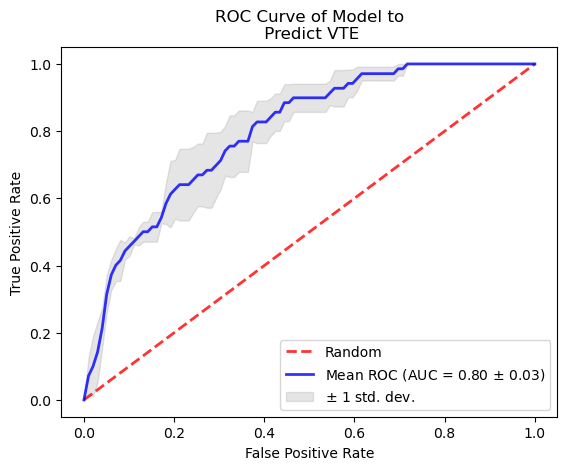

In [160]:
# Cross validation with 6 splits

# Create classifier using SVM
max_AUROC = 0

for random_state in range(270,272):
    for gamma in ['scale', 'auto']:
        C = 1
        for weight in ['balanced', {1:2}, {1:3}, {1:4}]:
            while C <= 2:
                cv = StratifiedKFold(n_splits = 3, random_state = random_state, shuffle = True)
                classifier = svm.SVC(kernel = "rbf", random_state = random_state, class_weight = weight, C=C, gamma = gamma)
                score = cross_val_score(classifier, X, y, cv = cv, scoring = 'roc_auc')
                if score.mean() > max_AUROC:
                    max_AUROC = score.mean()
                    max_gamma = gamma
                    max_weight = weight
                    max_C = C
                    max_random_state = random_state
                C += 0.1
cv = StratifiedKFold(n_splits = 3, random_state = max_random_state, shuffle = True)
classifier = svm.SVC(kernel = "rbf", random_state = max_random_state, class_weight = max_weight, C=max_C, gamma = max_gamma)


Scores(cv, classifier, X, y)
Kappa(cv, classifier, X, y)
print("\n\n SVM Model")
print(max_C, max_weight, max_gamma, max_random_state)
Curve(cv, classifier, X, y)

Accuracy Score: 0.83 ± 0.01
ROC_AUC Score: 0.71 ± 0.02
Average Precision Score: 0.43 ± 0.02
F1 Score: 0.80 ± 0.02
Recall: 0.26 ± 0.04


 Random Forest Model
81 True 132 balanced gini


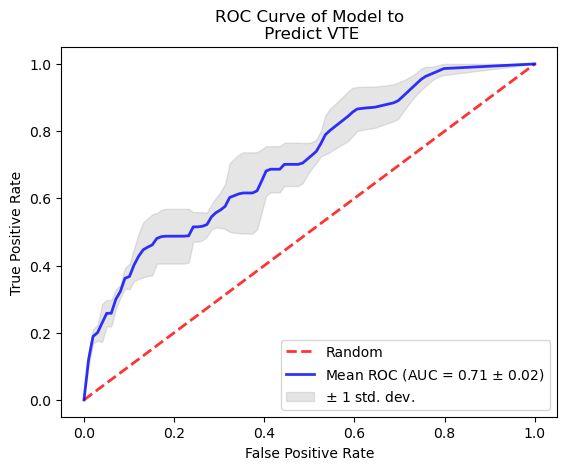

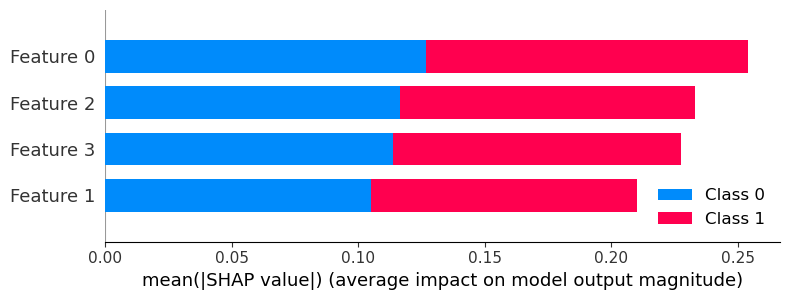

In [143]:
# Create classifier using Random Forest
max_AUROC = 0
for random_state in range(131,134):
    C = 50
    for criterion in ['gini', 'entropy', 'log_loss']:
        for weight in ['balanced', 'balanced_subsample', {1:2}, {1:3}, {1:4}]:
            for bootstrap in [True, False]:
                while C <= 100:
                    cv = StratifiedKFold(n_splits = 3, random_state = random_state, shuffle = True)
                    classifier = RandomForestClassifier(n_estimators = C, bootstrap = bootstrap, random_state = random_state, class_weight = weight, criterion = criterion)
                    score = cross_val_score(classifier, X, y, cv = cv, scoring = 'roc_auc')
                    if score.mean() > max_AUROC:
                        max_AUROC = score.mean()
                        max_criterion = criterion
                        max_weight = weight
                        max_C = C
                        max_random_state = random_state
                        max_strap = bootstrap
                    C += 1

cv = StratifiedKFold(n_splits = 3, random_state = max_random_state, shuffle = True)
classifier = RandomForestClassifier(n_estimators = max_C, bootstrap = max_strap, random_state = max_random_state, class_weight = max_weight, criterion = max_criterion)
Scores(cv, classifier, X, y)
print("\n\n Random Forest Model")
print(max_C, max_strap, max_random_state, max_weight, max_criterion)
Curve(cv, classifier, X, y)

# Experimenting with SHAP values
X_train, X_test, y_train, y_test = model_selection.train_test_split(X, y, test_size=0.3, random_state=max_random_state)
classifier.fit(X_train, y_train)
y_pred = classifier.predict(X_test)
explainer = shap.Explainer(classifier)
shap_values = explainer.shap_values(X_test)
shap.summary_plot(shap_values, X_test)

Accuracy Score: 0.82 ± 0.01
ROC_AUC Score: 0.75 ± 0.05
Average Precision Score: 0.40 ± 0.08
F1 Score: 0.76 ± 0.01
Recall: 0.06 ± 0.02


 Gradient Boosting Decision Tree Model
10 friedman_mse 291 log_loss 1


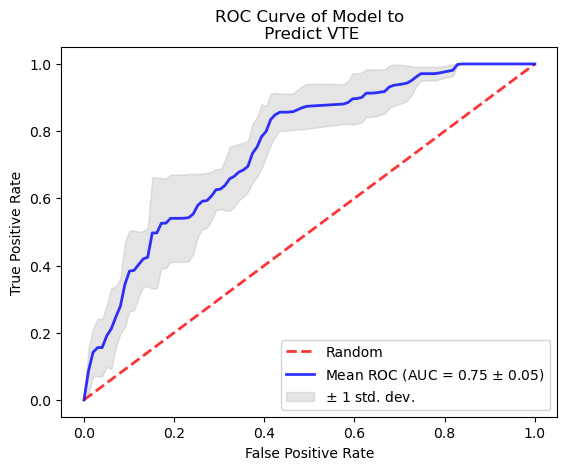

No data for colormapping provided via 'c'. Parameters 'vmin', 'vmax' will be ignored


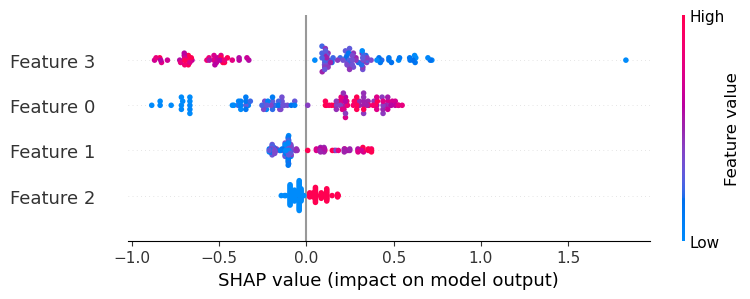

In [127]:
# Create classifier using Gradient Boosted Decision Tree
max_AUROC = 0
for random_state in range(290,292):
    C = 10
    subsample = 1
    for loss in ['log_loss', 'exponential']:
        for criterion in ['friedman_mse', 'squared_error']:
            while C <= 10:
                while subsample <= 1:
                    cv = StratifiedKFold(n_splits = 3, random_state = random_state, shuffle = True)
                    classifier = GradientBoostingClassifier(subsample = subsample, n_estimators = C, random_state = random_state, loss=loss, criterion = criterion)                    
                    score = cross_val_score(classifier, X, y, cv = cv, scoring = 'roc_auc')
                    if score.mean() > max_AUROC:
                        max_AUROC = score.mean()
                        max_criterion = criterion
                        max_C = C
                        max_random_state = random_state
                        max_loss = loss
                        max_subsample = subsample
                    C += 1
                    subsample += 0.1

classifier = GradientBoostingClassifier(n_estimators = max_C, random_state = max_random_state, subsample = max_subsample, criterion = max_criterion, loss = max_loss)
Scores(cv, classifier, X, y)
print("\n\n Gradient Boosting Decision Tree Model")
print(max_C, max_criterion, max_random_state, max_loss, max_subsample)
Curve(cv, classifier, X, y)

# Experimenting with SHAP values
X_train, X_test, y_train, y_test = model_selection.train_test_split(X, y, test_size=0.3, random_state=max_random_state)
classifier.fit(X_train, y_train)
y_pred = classifier.predict(X_test)
explainer = shap.Explainer(classifier)
shap_values = explainer.shap_values(X_test)
shap.summary_plot(shap_values, X_test)

In [50]:
# Let's see what happens when we include injury severity score
# Set explanatory variables
X = data.iloc[:,3:8]

# preprocessing scale
scaler = StandardScaler().fit(X)
X = scaler.transform(X)

Accuracy Score: 0.72 ± 0.06
ROC_AUC Score: 0.80 ± 0.06
Average Precision Score: 0.48 ± 0.13
F1 Score: 0.74 ± 0.05


 SVM Model with ISS
1 balanced auto 271


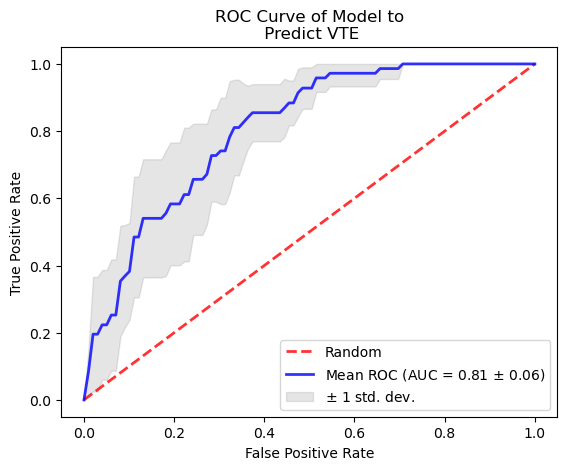

In [51]:
# iterate the random_state
max_AUROC = 0

for random_state in range(250,272):
    for gamma in ['scale', 'auto']:
        C = 1
        for weight in ['balanced', {1:2}, {1:3}, {1:4}]:
            while C <= 2:
                cv = StratifiedKFold(n_splits = 3, random_state = random_state, shuffle = True)
                classifier = svm.SVC(kernel = "rbf", random_state = random_state, class_weight = weight, C=C, gamma = gamma)
                score = cross_val_score(classifier, X, y, cv = cv, scoring = 'roc_auc')
                if score.mean() > max_AUROC:
                    max_AUROC = score.mean()
                    max_gamma = gamma
                    max_weight = weight
                    max_C = C
                    max_random_state = random_state
                C += 0.1
cv = StratifiedKFold(n_splits = 3, random_state = max_random_state, shuffle = True)
classifier = svm.SVC(kernel = "rbf", random_state = max_random_state, class_weight = max_weight, C=max_C, gamma = max_gamma)

# SVM modle with ISS
classifier = svm.SVC(kernel = "rbf", random_state = random_state, class_weight = "balanced", C = 1.4, gamma = "scale")
Scores(cv, classifier, X, y)
print("\n\n SVM Model with ISS")
print(max_C, max_weight, max_gamma, max_random_state)
Curve(cv, classifier, X, y)

Accuracy Score: 0.69 ± 0.03
ROC_AUC Score: 0.76 ± 0.05
Average Precision Score: 0.45 ± 0.10
F1 Score: 0.73 ± 0.03
Recall: 0.73 ± 0.15


 SVM Model Using Admission Data
1 balanced auto 271


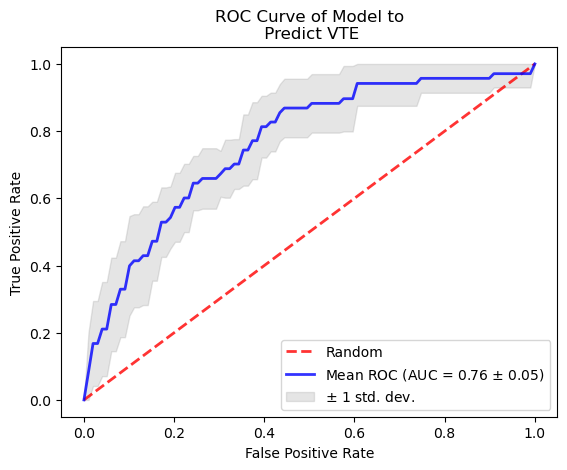

In [20]:
###################################################################################################################
# Admission data analysis using SVM 
# Variables of interest: BMI, age_at_injury, day_1_any_surg
# Set explanatory variables
X = data.iloc[:,[3,4,5]]

# preprocessing scale
scaler = StandardScaler().fit(X)
X = scaler.transform(X)

# Create classifier using SVM
max_AUROC = 0

for random_state in range(270,272):
    for gamma in ['scale', 'auto']:
        C = 1
        for weight in ['balanced', {1:2}, {1:3}, {1:4}]:
            while C <= 2:
                cv = StratifiedKFold(n_splits = 3, random_state = random_state, shuffle = True)
                classifier = svm.SVC(kernel = "rbf", random_state = random_state, class_weight = weight, C=C, gamma = gamma)
                score = cross_val_score(classifier, X, y, cv = cv, scoring = 'roc_auc')
                if score.mean() > max_AUROC:
                    max_AUROC = score.mean()
                    max_gamma = gamma
                    max_weight = weight
                    max_C = C
                    max_random_state = random_state
                C += 0.1
cv = StratifiedKFold(n_splits = 3, random_state = max_random_state, shuffle = True)
classifier = svm.SVC(kernel = "rbf", random_state = max_random_state, class_weight = max_weight, C=max_C, gamma = max_gamma)


Scores(cv, classifier, X, y)
print("\n\n SVM Model Using Admission Data")
print(max_C, max_weight, max_gamma, max_random_state)
Curve(cv, classifier, X, y)

Accuracy Score: 0.64 ± 0.03
ROC_AUC Score: 0.68 ± 0.07
Average Precision Score: 0.37 ± 0.10
F1 Score: 0.68 ± 0.02
Recall: 0.77 ± 0.13


 SVM Model Using Admission Data
1 balanced auto 271


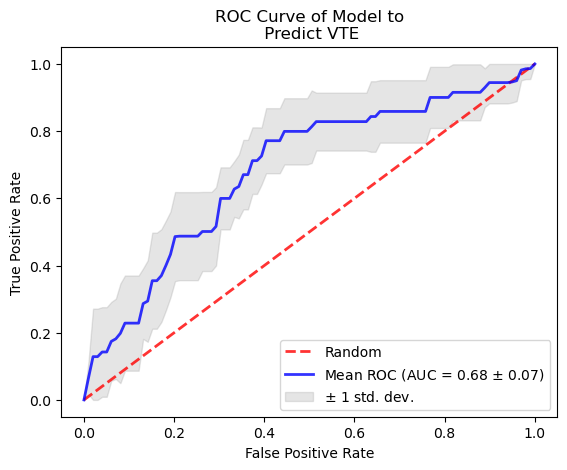

In [39]:
###################################################################################################################
data = data.dropna(subset = ['bmi_grp', 'first_ppp_ttpeak', 'age_at_injury', 'vte', 'day_1_any_surg', 'iss'])

# Admission data analysis using SVM 
# Variables of interest: BMI_grp, age_at_injury, day_1_any_surg
# Set explanatory variables
X = data.iloc[:,[37,4,5]]

# preprocessing scale
scaler = StandardScaler().fit(X)
X = scaler.transform(X)

# Create classifier using SVM
max_AUROC = 0

for random_state in range(270,272):
    for gamma in ['scale', 'auto']:
        C = 1
        for weight in ['balanced', {1:2}, {1:3}, {1:4}]:
            while C <= 2:
                cv = StratifiedKFold(n_splits = 3, random_state = random_state, shuffle = True)
                classifier = svm.SVC(kernel = "rbf", random_state = random_state, class_weight = weight, C=C, gamma = gamma)
                score = cross_val_score(classifier, X, y, cv = cv, scoring = 'roc_auc')
                if score.mean() > max_AUROC:
                    max_AUROC = score.mean()
                    max_gamma = gamma
                    max_weight = weight
                    max_C = C
                    max_random_state = random_state
                C += 0.1
cv = StratifiedKFold(n_splits = 3, random_state = max_random_state, shuffle = True)
classifier = svm.SVC(kernel = "rbf", random_state = max_random_state, class_weight = max_weight, C=max_C, gamma = max_gamma)


Scores(cv, classifier, X, y)
print("\n\n SVM Model Using Admission Data")
print(max_C, max_weight, max_gamma, max_random_state)
Curve(cv, classifier, X, y)